# Week 17 — Final Held-Out Test Evaluation

## Purpose

Evaluate the final frozen Configuration D EEGNet on the untouched
held-out test subjects.

This is the final subject-independent evaluation of the primary
NeuroSignalLab model.

## Frozen model

The evaluated model is the existing checkpoint:

`models/config_d_seed42_best.pt`

Configuration:

- EEGNet Configuration D
- seed = 42
- learning rate = 1e-3
- dropout = 0.5
- weight decay = 1e-4
- no max-norm constraints
- selected checkpoint epoch = 19

The model will NOT be retrained or modified before final evaluation.

## Frozen preprocessing

- 64 EEG channels
- common-average reference
- 7–30 Hz FIR filtering
- 160 Hz sampling rate
- +1 to +4 second analysis window
- 481 samples per trial
- stored data in volts
- neural-network input multiplied by 1e6
- label 0 = imagined left fist
- label 1 = imagined right fist

## Test set

The existing fixed subject split will be used.

Only subjects marked `test` in:

`results/week9_subject_split.csv`

will be included.

No test subject or trial will be excluded based on model performance.

## Metrics

Primary metric:

- balanced accuracy

Secondary descriptive metrics:

- accuracy
- macro F1
- confusion matrix
- balanced accuracy for each test subject

## Final evaluation rule

The test set will be evaluated once using the frozen checkpoint.

The test result will be reported whether it is better or worse than
the validation result.

## Scope decision

The optional CHB-MIT seizure extension is skipped.

The final sprint will focus on completing, documenting, deploying,
and releasing the motor-imagery project.

### Imports and paths

In [20]:
from pathlib import Path

import numpy as np
import pandas as pd
import sys
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix, 
    ConfusionMatrixDisplay
)


ROOT = Path.cwd().parent

sys.path.insert(0, str(ROOT / "src"))

from neurosignallab.inference import (load_eegnet, predict_trial)

checkpoint_path = (ROOT / "models" / "config_d_seed42_best.pt")

split_path = (ROOT / "results" / "week9_subject_split.csv")

model, checkpoint, device = load_eegnet(checkpoint_path)

print("Model:", checkpoint["model_name"])
print(
    "Validation BA:",
    checkpoint["validation_balanced_accuracy"]
)
print("Device:", device)

Model: EEGNet_Config_D
Validation BA: 0.6277011922503726
Device: mps


### Find test subjects

In [5]:
split_df = pd.read_csv(split_path)

test_subjects = split_df[split_df["split"] == "test"]["subject"].to_numpy()

print("Number of test subjects:", len(test_subjects)
)

print("Test subjects:", test_subjects)

Number of test subjects: 17
Test subjects: [  5   8  22  26  28  46  57  71  73  74  84  86  90 103 104 106 109]


### Load processed EEG

In [6]:
X = np.load(ROOT / "data" / "processed" / "X_motor_imagery.npy", mmap_mode="r")

y = np.load(ROOT / "data" / "processed" / "y_motor_imagery.npy")

subjects = np.load(ROOT / "data" / "processed" / "subjects.npy")

runs = np.load(ROOT / "data" / "processed" / "runs.npy")

### Extract test trials

In [7]:
test_mask = np.isin(subjects, test_subjects)

X_test = X[test_mask]
y_test = y[test_mask]
subjects_test = subjects[test_mask]
runs_test = runs[test_mask]

print("Test trials:", len(X_test))

print("Test shape:", X_test.shape)

print("Unique test subjects:", len(np.unique(subjects_test)))

Test trials: 757
Test shape: (757, 64, 481)
Unique test subjects: 17


### Final test subject predictions

In [8]:
predictions = []

for i in range(len(X_test)):
    result = predict_trial(
        model,
        X_test[i],
        checkpoint,
        device
    )

    predictions.append(result["prediction"])

predictions = np.array(predictions)

print("Number of predictions:", len(predictions))

print("First 10 predictions:", predictions[:10])

print("First 10 true labels:", y_test[:10])

/Users/heihei/Desktop/neurosignallab/.venv/lib/python3.13/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(


Number of predictions: 757
First 10 predictions: [1 1 1 1 1 0 1 1 1 1]
First 10 true labels: [1 0 0 1 1 0 0 1 0 1]


### Calculate metrics

In [10]:
accuracy = accuracy_score(y_test, predictions)

balanced_accuracy = balanced_accuracy_score(y_test, predictions)

macro_f1 = f1_score(y_test, predictions, average="macro")

cm = confusion_matrix(y_test, predictions)

print("Accuracy:", accuracy)

print("Balanced accuracy:", balanced_accuracy)

print("Macro F1:", macro_f1)

print("Confusion matrix:")

print(cm)

Accuracy: 0.5759577278731837
Balanced accuracy: 0.575589836660617
Macro F1: 0.5720866755302756
Confusion matrix:
[[254 126]
 [195 182]]


### Check subject level performance

In [11]:
subject_results = []

for subject in test_subjects:
    subject_mask = subjects_test == subject

    subject_true = y_test[subject_mask]
    subject_pred = predictions[subject_mask]

    subject_ba = balanced_accuracy_score(subject_true, subject_pred)

    subject_accuracy = accuracy_score(subject_true, subject_pred)

    subject_f1 = f1_score(subject_true, subject_pred, average="macro")

    subject_results.append({
        "subject": subject,
        "n_trials": len(subject_true),
        "balanced_accuracy": subject_ba,
        "accuracy": subject_accuracy,
        "macro_f1": subject_f1
    })


subject_results = pd.DataFrame(subject_results)

subject_results

,subject,n_trials,balanced_accuracy,accuracy,macro_f1
0,5,45,0.458333,0.466667,0.453441
1,8,45,0.521739,0.511111,0.375000
2,22,45,0.583992,0.577778,0.545455
3,26,45,0.535714,0.533333,0.533333
4,28,45,0.495059,0.488889,0.449761
5,46,45,0.662055,0.666667,0.649351
6,57,45,0.497024,0.488889,0.484818
7,71,45,0.801383,0.800000,0.799604
8,73,42,0.642857,0.642857,0.642655
9,74,43,0.531385,0.534884,0.522222


In [12]:
print(
    "Mean subject BA:",
    subject_results["balanced_accuracy"].mean()
)

print(
    "Median subject BA:",
    subject_results["balanced_accuracy"].median()
)

print(
    "Lowest subject BA:",
    subject_results["balanced_accuracy"].min()
)

print(
    "Highest subject BA:",
    subject_results["balanced_accuracy"].max()
)

Mean subject BA: 0.5775864693703568
Median subject BA: 0.5810276679841897
Lowest subject BA: 0.45833333333333337
Highest subject BA: 0.8013833992094861


### Save final results

In [13]:
results_dir = ROOT / "results"

results_dir.mkdir(exist_ok=True)

In [14]:
final_metrics = pd.DataFrame({
    "metric": [
        "accuracy",
        "balanced_accuracy",
        "macro_f1"
    ],
    "value": [
        accuracy,
        balanced_accuracy,
        macro_f1
    ]
})

final_metrics

,metric,value
0,accuracy,0.575958
1,balanced_accuracy,0.575590
2,macro_f1,0.572087


In [19]:
final_metrics.to_csv(results_dir / "week17_final_test_metrics.csv", index=False)

subject_results.to_csv(results_dir / "week17_final_subject_metrics.csv", index=False)

final_predictions = pd.DataFrame({
    "subject": subjects_test,
    "run": runs_test,
    "true_label": y_test,
    "prediction": predictions
})

final_predictions.to_csv(results_dir / "week17_final_predictions.csv", index=False)

final_predictions.head()

,subject,run,true_label,prediction
0,5,4,1,1
1,5,4,0,1
2,5,4,0,1
3,5,4,1,1
4,5,4,1,1


### Create final figure

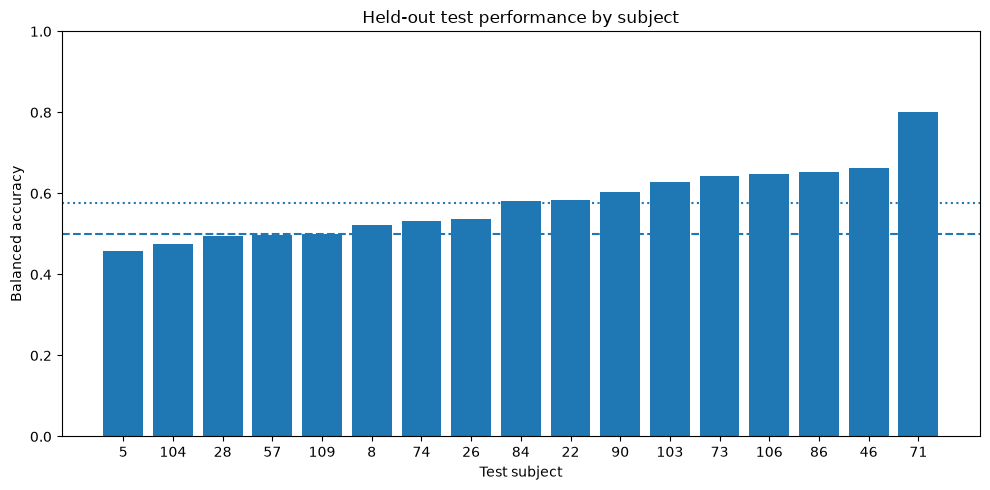

In [18]:
plot_data = subject_results.sort_values("balanced_accuracy")

figures_dir = ROOT / "figures"

figures_dir.mkdir(exist_ok=True)

plt.figure(figsize=(10, 5))

plt.bar(plot_data["subject"].astype(str), plot_data["balanced_accuracy"])

plt.axhline(0.5, linestyle="--")

plt.axhline(balanced_accuracy, linestyle=":")

plt.xlabel("Test subject")

plt.ylabel("Balanced accuracy")

plt.title("Held-out test performance by subject")

plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(figures_dir / "week17_test_subject_performance.png", dpi=300)

plt.show()

### Confusion matrix figure

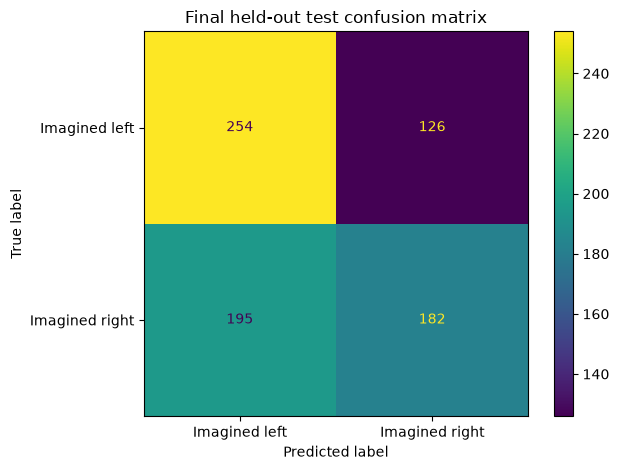

In [21]:
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Imagined left",
        "Imagined right"
    ]
)

display.plot()

plt.title("Final held-out test confusion matrix")

plt.tight_layout()

plt.savefig(figures_dir / "week17_test_confusion_matrix.png", dpi=300)

plt.show()

## Week 17 conclusion

The Configuration D EEGNet was evaluated once on the final held-out test set.

The test set contained:

- 17 previously unseen subjects
- 757 motor-imagery trials

Final performance:

- Accuracy: 0.5760
- Balanced accuracy: 0.5756
- Macro F1: 0.5721

The confusion matrix was:

- true left → predicted left: 254
- true left → predicted right: 126
- true right → predicted left: 195
- true right → predicted right: 182

Performance varied substantially across unseen subjects.

- Mean subject balanced accuracy: 0.5776
- Median subject balanced accuracy: 0.5810
- Lowest subject balanced accuracy: 0.4583
- Highest subject balanced accuracy: 0.8014

The held-out balanced accuracy was lower than the development
validation balanced accuracy of 0.6277. This indicates that the
validation estimate was somewhat optimistic for completely unseen
subjects.

The model also showed asymmetric class performance on the test set,
performing better on imagined-left trials than imagined-right trials.

The final result remains a locked estimate of
subject-independent generalization for the selected model.

The main conclusion is that EEGNet learned signal structure that
generalized above chance to unseen subjects, but substantial
between-subject variability remains a major limitation of
subject-independent motor-imagery EEG decoding.